# EDA Dataset

Mengenal dataset sebelum PCD: komposisi, variasi kondisi, kualitas foto, bukti data primer, karakter visual, objek yang sangat mirip, dan contoh foto. Data dibaca dari `data/metadata.csv` hasil `prepare_dataset`.

Angka di notebook ini mengikuti `prepare_dataset` terakhir. Data Farhan dan Mafaza sudah lengkap, sedangkan data Jefri masih dilengkapi. Notebook ini dijalankan ulang setiap kali data bertambah.

## 1. Komposisi dataset

Target akuisisi adalah 50 objek per kelas, dengan target 16–17 objek per anggota per kelas dan batas minimum 13 (`docs/panduan-pengambilan-data.md`). Pemeriksaan di bawah menunjukkan posisi saat ini terhadap target tersebut. Kekurangan akan dilengkapi sebelum dataset final di Progress 3.

In [63]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from core.config import CLASSES, METADATA_CSV, REPORTS_DIR

FIGURES = REPORTS_DIR / "dataset"
SPLITS = ["train", "val", "test"]

photos = pd.read_csv(METADATA_CSV)
photos = photos[photos["split"].notna()].reset_index(drop=True)
objects = photos.drop_duplicates("object_id").reset_index(drop=True)
print(f"foto: {len(photos)} | objek: {len(objects)}")

foto: 276 | objek: 138


In [64]:
TARGET_PER_CLASS = 50
MIN_PER_MEMBER = 13
MAX_MEMBER_SHARE = 0.5
MAX_CLASS_RATIO = 1.5

MEMBER_TARGETS = pd.DataFrame(
    {"Farhan": [17, 16, 17], "Jefri": [16, 17, 17], "Mafaza": [17, 17, 16]},
    index=CLASSES,
)

member_counts = pd.crosstab(objects["label"], objects["member"]).reindex(CLASSES)
totals = member_counts.sum(axis=1)
display(member_counts.assign(
    total=totals,
    target=TARGET_PER_CLASS,
    persen_target=(totals / TARGET_PER_CLASS * 100).round().astype(int),
))

remaining = (MEMBER_TARGETS - member_counts).clip(lower=0)
display(remaining.assign(total=remaining.sum(axis=1)).rename_axis("sisa menuju target"))

under = [
    f"{member} di {label} ({count})"
    for label, row in member_counts.iterrows()
    for member, count in row.items()
    if count < MIN_PER_MEMBER
]
over = [
    f"{member} di {label} ({share:.0%})"
    for label, row in member_counts.div(totals, axis=0).iterrows()
    for member, share in row.items()
    if share > MAX_MEMBER_SHARE
]
ratio = totals.max() / totals.min()

pd.DataFrame({
    "aturan kuota": [
        f"minimal {MIN_PER_MEMBER} objek per anggota per kelas",
        f"satu anggota maksimal {MAX_MEMBER_SHARE:.0%} dari satu kelas",
        f"rasio kelas terbanyak/tersedikit maksimal {MAX_CLASS_RATIO}",
    ],
    "hasil": [", ".join(under) or "terpenuhi", ", ".join(over) or "terpenuhi", f"{ratio:.2f}"],
    "status": [
        "belum terpenuhi" if under else "terpenuhi",
        "belum terpenuhi" if over else "terpenuhi",
        "terpenuhi" if ratio <= MAX_CLASS_RATIO else "belum terpenuhi",
    ],
})

member,Farhan,Jefri,Mafaza,total,target,persen_target
label,,,,,,
plastik,17,10,17,44,50,88
kertas,17,14,17,48,50,96
kardus,18,11,17,46,50,92


,Farhan,Jefri,Mafaza,total
sisa menuju target,,,,
plastik,0,6,0,6
kertas,0,3,0,3
kardus,0,6,0,6


,aturan kuota,hasil,status
0,minimal 13 objek per anggota per kelas,"Jefri di plastik (10), Jefri di kardus (11)",belum terpenuhi
1,satu anggota maksimal 50% dari satu kelas,terpenuhi,terpenuhi
2,rasio kelas terbanyak/tersedikit maksimal 1.5,1.09,terpenuhi


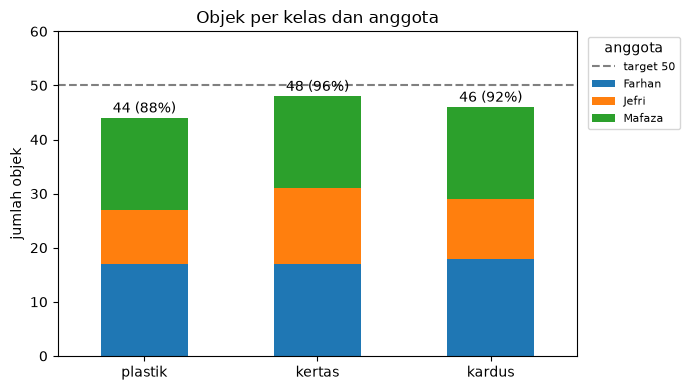

In [65]:
fig, ax = plt.subplots(figsize=(7, 4))
member_counts.plot.bar(stacked=True, ax=ax, rot=0)
ax.axhline(TARGET_PER_CLASS, color="gray", linestyle="--", label=f"target {TARGET_PER_CLASS}")
for position, total in enumerate(totals):
    ax.text(position, total + 1, f"{total} ({total / TARGET_PER_CLASS:.0%})", ha="center")
ax.set_xlabel("")
ax.set_ylim(0, TARGET_PER_CLASS * 1.2)
ax.set_ylabel("jumlah objek")
ax.set_title("Objek per kelas dan anggota")
ax.legend(title="anggota", fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
fig.savefig(FIGURES / "eda_composition.png", dpi=150)

In [66]:
split_counts = pd.crosstab(objects["label"], objects["split"]).reindex(index=CLASSES, columns=SPLITS)
display(split_counts.assign(total=split_counts.sum(axis=1)))

for column in ["member", "lighting", "condition"]:
    share = pd.crosstab(objects[column], objects["split"], normalize="columns").reindex(columns=SPLITS)
    display(share.round(2).rename_axis(f"{column} (proporsi per split)"))

split,train,val,test,total
label,,,,
plastik,31,6,7,44
kertas,33,7,8,48
kardus,33,6,7,46


split,train,val,test
member (proporsi per split),,,
Farhan,0.41,0.42,0.18
Jefri,0.22,0.32,0.36
Mafaza,0.37,0.26,0.45


split,train,val,test
lighting (proporsi per split),,,
dalam-alami,0.29,0.42,0.32
dalam-lampu,0.40,0.47,0.41
luar-teduh,0.11,0.11,0.09
luar-terang,0.20,0.00,0.18


split,train,val,test
condition (proporsi per split),,,
bersih,0.6,0.47,0.50
kotor,0.1,0.11,0.09
rusak,0.3,0.42,0.41


## 2. Variasi kondisi

In [67]:
subtypes = objects.groupby("label")["subtype"].value_counts().rename("objek").reset_index()
subtypes["persen dalam kelas"] = (
    subtypes["objek"] / subtypes.groupby("label")["objek"].transform("sum") * 100
).round(0).astype(int)
subtypes["label"] = pd.Categorical(subtypes["label"], categories=CLASSES, ordered=True)
subtypes.sort_values(["label", "objek"], ascending=[True, False]).set_index(["label", "subtype"])

objek  persen dalam kelas
label   subtype                                     
plastik kresek                11                  25
        botol                 11                  25
        wadah/tutup            9                  20
        bungkus snack          9                  20
        gelas cup              4                   9
kertas  lembaran utuh         15                  31
        diremas               14                  29
        dilipat/sobek         14                  29
        koran/struk            5                  10
kardus  kotak utuh            39                  85
        potongan/lembaran      7                  15

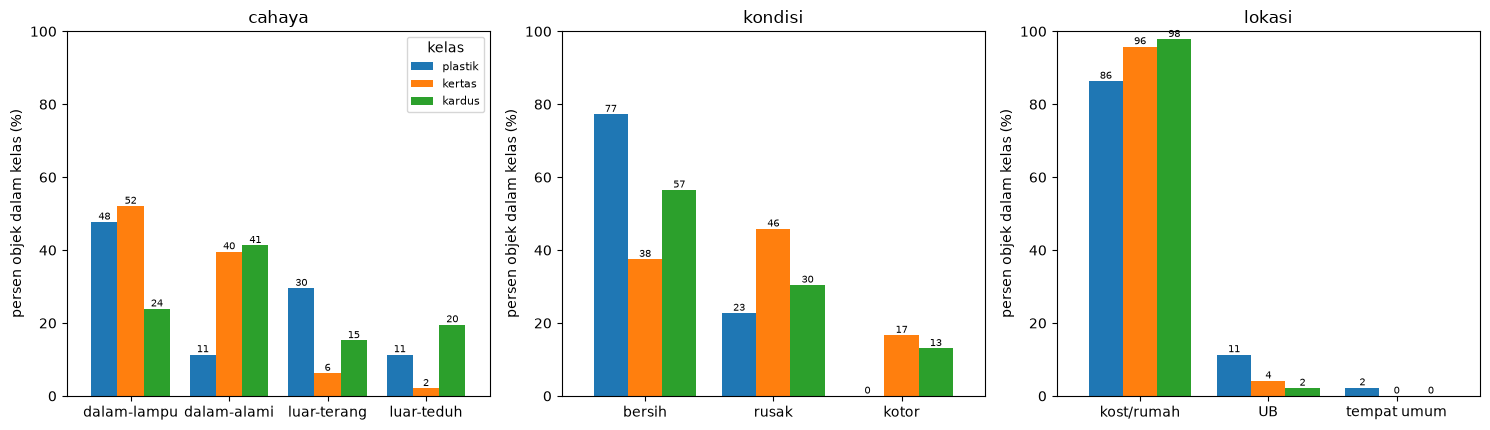

In [68]:
CONDITION_COLUMNS = ["lighting", "condition", "location"]
CONDITION_TITLES = {"lighting": "cahaya", "condition": "kondisi", "location": "lokasi"}

fig, axes = plt.subplots(1, len(CONDITION_COLUMNS), figsize=(15, 4.4))
for ax, column in zip(axes, CONDITION_COLUMNS):
    counts = pd.crosstab(objects[column], objects["label"]).reindex(columns=CLASSES)
    counts = counts.loc[counts.sum(axis=1).sort_values(ascending=False).index]
    share = counts.div(counts.sum(axis=0), axis=1) * 100
    share.plot.bar(ax=ax, rot=0, width=0.8, legend=False)
    for bars in ax.containers:
        ax.bar_label(bars, fmt="%.0f", fontsize=7)
    ax.set_title(CONDITION_TITLES[column])
    ax.set_xlabel("")
    ax.set_ylabel("persen objek dalam kelas (%)")
    ax.set_ylim(0, 100)
axes[0].legend(title="kelas", fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "eda_conditions.png", dpi=150, bbox_inches="tight")

### Korelasi palsu

Kalau sebuah kondisi hampir selalu muncul bersama kelas tertentu, model bisa belajar mengenali kondisi itu, bukan sampahnya. Kekuatan hubungan diukur dengan Cramér's V: 0 berarti tidak berhubungan, 1 berarti kondisi menentukan kelas sepenuhnya.

Besar hubungan dinilai dengan konvensi Cohen (1988, Bab 7): batas kecil, sedang, dan besar adalah 0,1, 0,3, dan 0,5, dibagi √df\*, dengan df\* = min(baris, kolom) − 1. Untuk tabel kelas × faktor dengan tiga kategori atau lebih, df\* = 2 sehingga batasnya 0,07, 0,21, dan 0,35.

In [69]:
from scipy.stats import chi2_contingency


def cramers_v(a: pd.Series, b: pd.Series) -> float:
    """Kekuatan hubungan dua variabel kategori, dari 0 sampai 1."""
    table = pd.crosstab(a, b)
    chi2 = chi2_contingency(table, correction=False)[0]
    return float(np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1))))


def effect_size(v: float, df: int) -> str:
    """Besar efek Cramér's V menurut Cohen (1988), disesuaikan dengan derajat kebebasan."""
    small, medium, large = (x / np.sqrt(df) for x in (0.1, 0.3, 0.5))
    if v >= large:
        return "besar"
    if v >= medium:
        return "sedang"
    return "kecil" if v >= small else "sangat kecil"


def association(a: pd.Series, b: pd.Series) -> dict:
    v = cramers_v(a, b)
    df = min(a.nunique(), b.nunique()) - 1
    return {"cramers_v": round(v, 2), "df*": df, "kekuatan": effect_size(v, df)}


factors = ["member", *CONDITION_COLUMNS]
pd.DataFrame([association(objects["label"], objects[column]) for column in factors], index=factors)

,cramers_v,df*,kekuatan
member,0.05,2,sangat kecil
lighting,0.32,2,sedang
condition,0.25,2,sedang
location,0.15,2,kecil


In [70]:
from core.config import ROOT

background = pd.read_csv(ROOT / "dataset" / "labels" / "background_sample.csv").merge(photos, on="raw_path")
display(pd.crosstab(background["label"], background["background"]).reindex(CLASSES))
result = association(background["label"], background["background"])
print(
    f"Cramér's V kelas-latar (40 foto berlabel): {result['cramers_v']:.2f} "
    f"({result['kekuatan']}, df* = {result['df*']})"
)

background,polos,ramai
label,,
plastik,6,8
kertas,12,1
kardus,8,5


Cramér's V kelas-latar (40 foto berlabel): 0.43 (sedang, df* = 1)


Tidak ada faktor yang berhubungan besar dengan kelas. Cahaya berhubungan sedang dan berasal dari cara akuisisi: plastik paling sering difoto di luar-terang (13 dari 44), sedangkan kertas hampir selalu di dalam ruangan (44 dari 48). Kondisi juga sedang: plastik kebanyakan bersih (34 dari 44), sedangkan kertas paling sering rusak (22 dari 48), sebagian wajar karena sifat bahannya dan sebagian karena pilihan objek saat akuisisi. Hubungan ini perlu diwaspadai sebagai jalan pintas bagi model. Hubungan dengan anggota kini sangat kecil karena kuota antaranggota sudah lebih seimbang. Hubungan dengan latar masih dihitung dari 40 sampel berlabel dan terutama berasal dari kertas yang hampir selalu berlatar polos.

## 3. Kualitas foto

Setiap foto dibuka untuk mengukur resolusi asli, ketajaman, kecerahan, dan kontras. Ketajaman diukur dengan variance of Laplacian pada citra grayscale 512 px: makin kecil, makin buram. Kecerahan adalah rata-rata intensitas (0–255) dan kontras adalah simpangan bakunya.

In [71]:
import cv2
from tqdm.auto import tqdm

from core.config import DATA_DIR
from core.image import load_image
from dataset.metadata import measure_photo

quality = pd.DataFrame([measure_photo(DATA_DIR / path) for path in tqdm(photos["raw_path"])])
photos = pd.concat([photos, quality], axis=1)

photos["resolution"] = photos["width"].astype(str) + "x" + photos["height"].astype(str)
pd.crosstab(photos["resolution"], photos["member"])

100%|██████████| 276/276 [00:28<00:00,  9.67it/s]


member,Farhan,Jefri,Mafaza
resolution,,,
1156x868,0,11,0
1200x1600,0,0,71
1280x960,0,3,2
1600x1200,0,0,14
3000x4000,102,0,0
3472x4624,0,8,0
4000x3000,2,0,0
868x1156,0,33,0
900x1600,0,9,0


,sharpness,brightness,contrast
label,,,
plastik,380.7,109.3,42.7
kertas,319.7,106.2,45.4
kardus,554.8,122.0,49.8


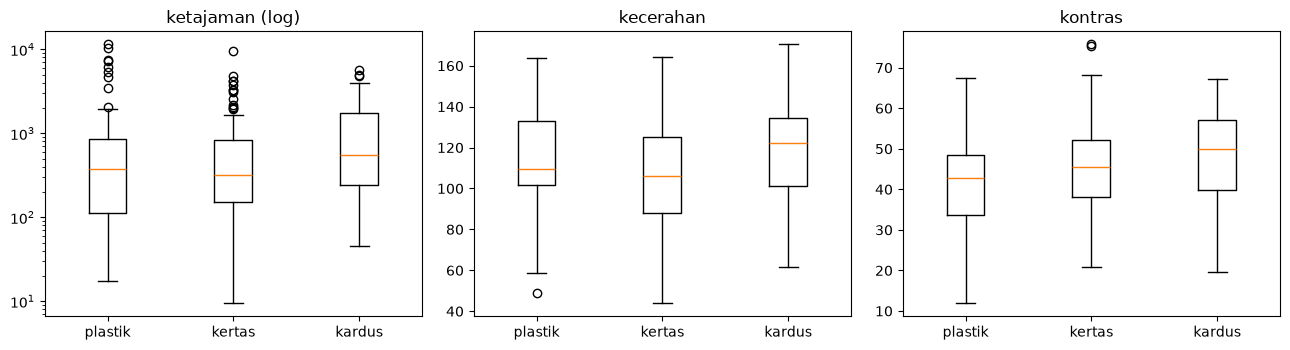

In [72]:
METRICS = {"sharpness": "ketajaman (log)", "brightness": "kecerahan", "contrast": "kontras"}

fig, axes = plt.subplots(1, len(METRICS), figsize=(13, 3.6))
for ax, (column, title) in zip(axes, METRICS.items()):
    ax.boxplot([photos.loc[photos["label"] == label, column] for label in CLASSES], tick_labels=CLASSES)
    ax.set_title(title)
    if column == "sharpness":
        ax.set_yscale("log")
fig.tight_layout()
fig.savefig(FIGURES / "eda_quality.png", dpi=150)

photos.groupby("label")[list(METRICS)].median().reindex(CLASSES).round(1)

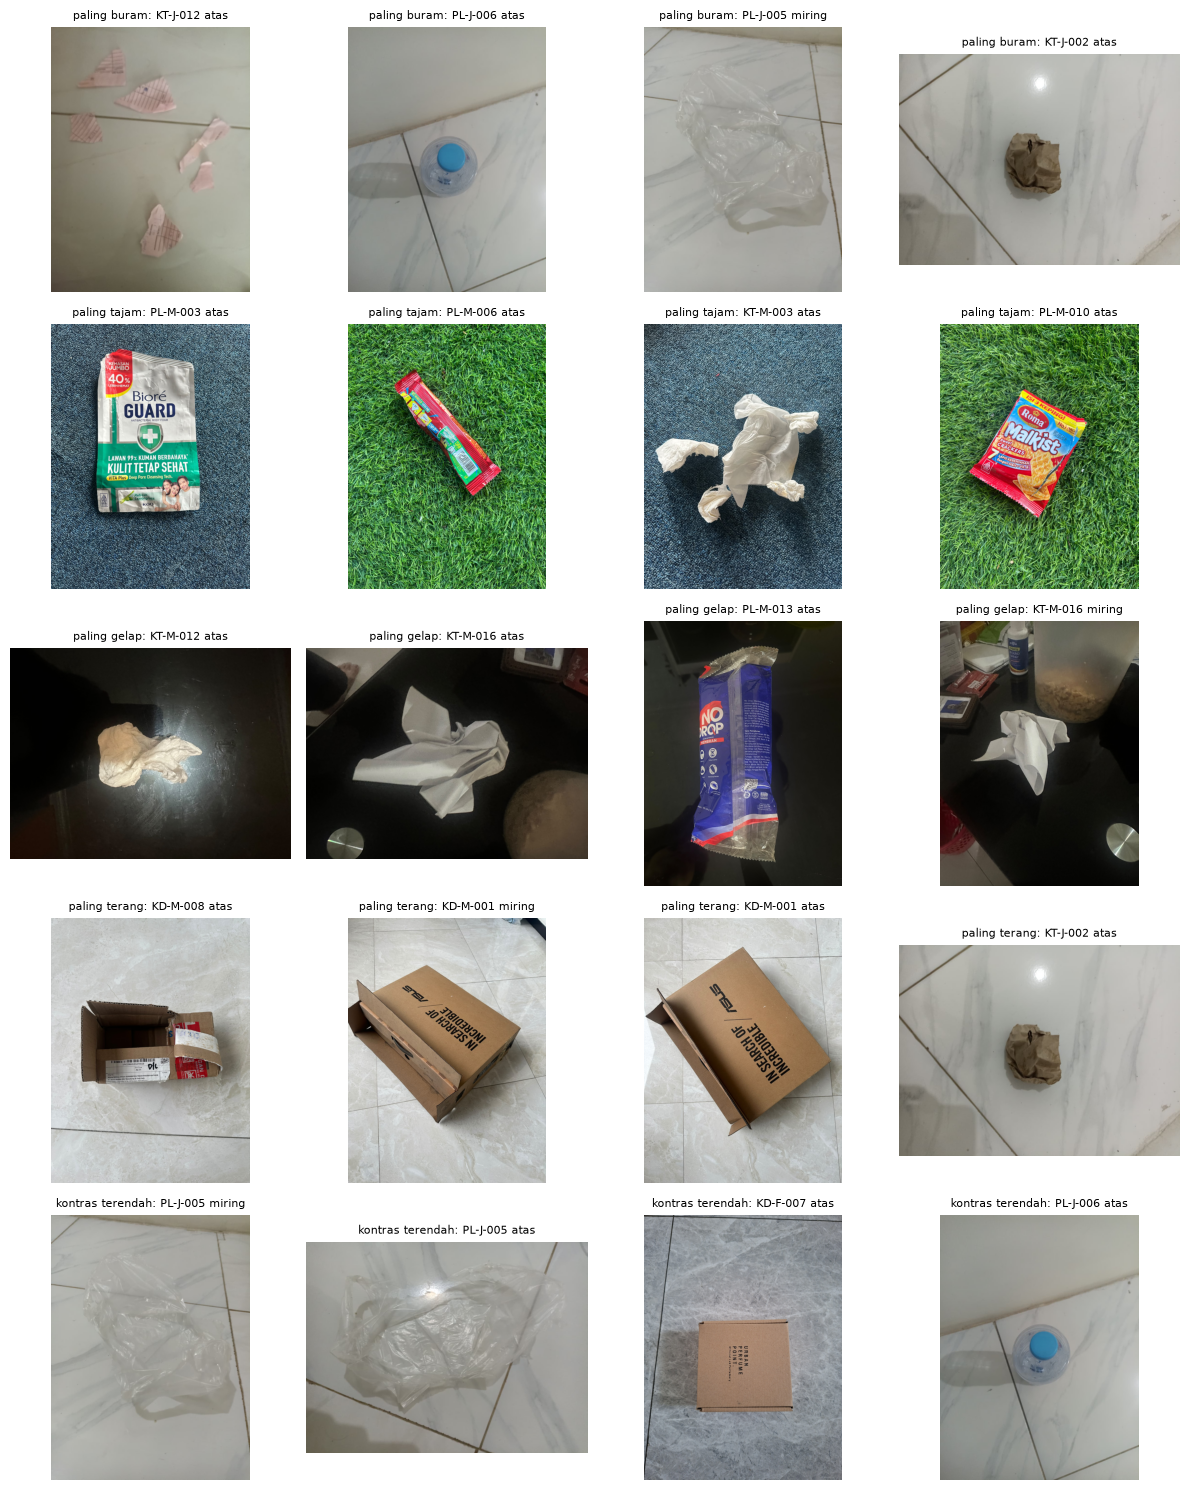

In [73]:
EXTREMES = [
    ("paling buram", photos.nsmallest(4, "sharpness")),
    ("paling tajam", photos.nlargest(4, "sharpness")),
    ("paling gelap", photos.nsmallest(4, "brightness")),
    ("paling terang", photos.nlargest(4, "brightness")),
    ("kontras terendah", photos.nsmallest(4, "contrast")),
]

fig, axes = plt.subplots(len(EXTREMES), 4, figsize=(12, 3 * len(EXTREMES)))
for row, (title, subset) in zip(axes, EXTREMES):
    for ax, photo in zip(row, subset.itertuples()):
        image = cv2.cvtColor(load_image(DATA_DIR / photo.raw_path), cv2.COLOR_BGR2RGB)
        ax.imshow(image)
        ax.set_title(f"{title}: {photo.object_id} {photo.view}", fontsize=8)
        ax.axis("off")
fig.tight_layout()
fig.savefig(FIGURES / "eda_quality_extremes.png", dpi=120)

Tidak ada foto yang rusak. Nilai ekstrem lebih banyak ditentukan oleh latar daripada kualitas foto: foto paling tajam berlatar rumput sintetis atau karpet bertekstur, sedangkan foto paling buram sebenarnya fokus tetapi berlatar lantai marmer yang mulus. Foto paling gelap dan paling terang juga dipengaruhi warna latarnya. Ukuran yang lebih adil adalah yang dihitung di area objek saja, setelah segmentasi. Foto dengan kontras terendah, seperti plastik bening atau kardus di lantai yang warnanya mirip, menjadi kandidat kasus sulit untuk segmentasi.

## 4. Proses akuisisi

Timeline diambil dari tanggal di Form sehingga mencakup semua anggota. Resolusi dan EXIF dipakai untuk mengecek kepatuhan protokol unggah: foto asli HP menyimpan EXIF dan beresolusi penuh, sedangkan foto yang dikirim lewat aplikasi chat dikompres dan kehilangan EXIF. Foto Mafaza dan sebagian besar foto Jefri ternyata dikirim lewat WhatsApp sebelum diunggah, sehingga resolusinya turun ke sekitar 1200–1600 px dan EXIF-nya hilang.

In [74]:
photos["has_exif"] = photos["taken_at"].notna()
display(pd.crosstab(photos["member"], photos["has_exif"]).rename(columns={True: "ada EXIF", False: "tanpa EXIF"}))
pd.crosstab(photos["member"], photos["camera"].replace("", "(tidak ada)"))

has_exif,tanpa EXIF,ada EXIF
member,,
Farhan,0,104
Jefri,62,8
Mafaza,102,0


camera,(tidak ada),Xiaomi M2101K7BNY,samsung Galaxy A56 5G
member,,,
Farhan,0,0,104
Jefri,62,8,0
Mafaza,102,0,0


tanggal EXIF berbeda dengan tanggal di Form: 0 dari 112 foto ber-EXIF


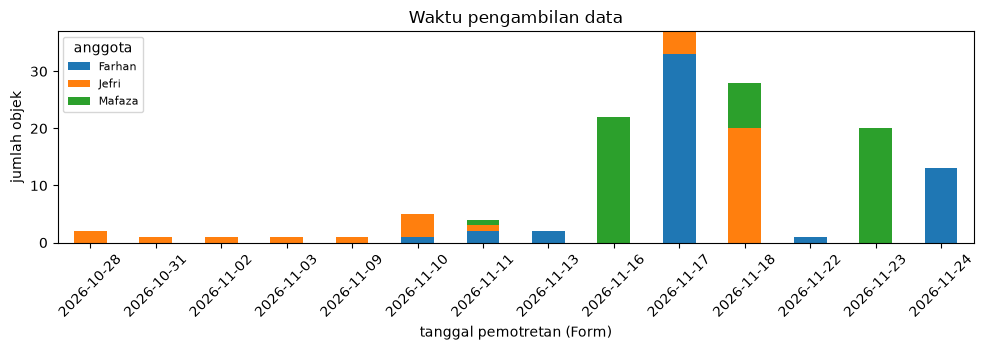

In [75]:
with_exif = photos[photos["has_exif"]]
mismatch = with_exif["taken_at"].dt.date.astype(str) != with_exif["taken_on"].astype(str)
print(f"tanggal EXIF berbeda dengan tanggal di Form: {mismatch.sum()} dari {len(with_exif)} foto ber-EXIF")

timeline = pd.crosstab(objects["taken_on"], objects["member"])
fig, ax = plt.subplots(figsize=(10, 3.6))
timeline.plot.bar(stacked=True, ax=ax, rot=45)
ax.set_xlabel("tanggal pemotretan (Form)")
ax.set_ylabel("jumlah objek")
ax.set_title("Waktu pengambilan data")
ax.legend(title="anggota", fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / "eda_acquisition_timeline.png", dpi=150)

## 5. Hue, saturation, dan value per kelas

Setiap foto diperkecil ke 256 px, lalu hue, saturation, dan value diukur di area tengah (60% lebar dan tinggi) karena objek berada di tengah. Area ini masih memuat sebagian latar, jadi hasilnya adalah gambaran kasar sebelum segmentasi.

Hue di OpenCV bernilai 0–179:

| Hue | Warna |
|---|---|
| 0–10 | merah |
| 10–25 | oranye, cokelat |
| 25–35 | kuning |
| 35–85 | hijau |
| 85–100 | toska |
| 100–130 | biru |
| 130–145 | ungu |
| 145–170 | pink, magenta |
| 170–179 | merah |

In [76]:
THUMB_SIZE = 256
CENTER = 0.6


def thumbnail(raw_path: str) -> np.ndarray:
    image = load_image(DATA_DIR / raw_path)
    scale = THUMB_SIZE / max(image.shape[:2])
    return cv2.resize(image, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)


def center_region(image: np.ndarray) -> np.ndarray:
    height, width = image.shape[:2]
    dy, dx = int(height * (1 - CENTER) / 2), int(width * (1 - CENTER) / 2)
    return image[dy : height - dy, dx : width - dx]


thumbs = {path: thumbnail(path) for path in tqdm(photos["raw_path"])}
hsv = {path: cv2.cvtColor(center_region(image), cv2.COLOR_BGR2HSV) for path, image in thumbs.items()}
photos["saturation"] = photos["raw_path"].map(lambda path: float(np.median(hsv[path][..., 1])))
photos["value"] = photos["raw_path"].map(lambda path: float(np.median(hsv[path][..., 2])))

100%|██████████| 276/276 [00:32<00:00,  8.62it/s]


,saturation,value
label,,
plastik,39.0,141.0
kertas,35.5,147.0
kardus,61.0,154.0


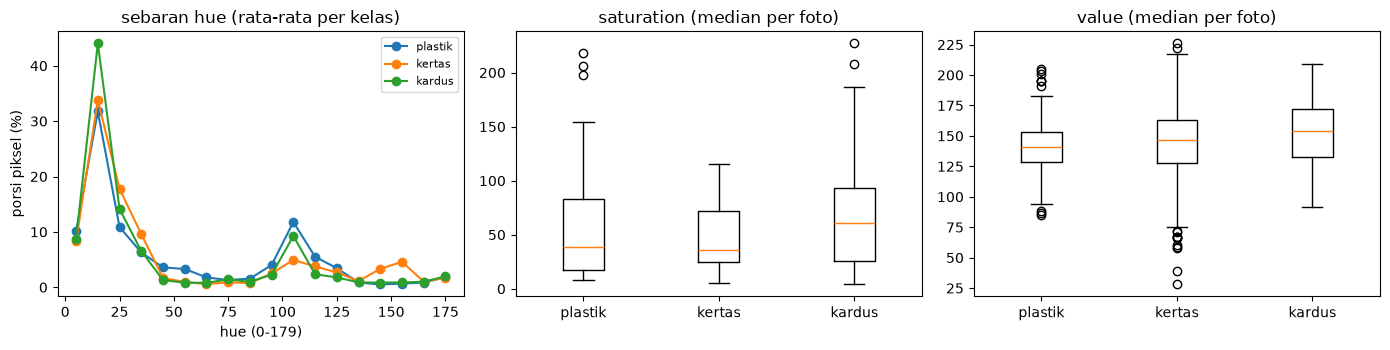

In [82]:
HUE_BINS = np.arange(0, 181, 10)


def hue_share(hsv_image: np.ndarray) -> np.ndarray:
    hue = hsv_image[..., 0]
    return np.histogram(hue, bins=HUE_BINS)[0] / hue.size * 100


fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for label in CLASSES:
    paths = photos.loc[photos["label"] == label, "raw_path"]
    share = np.mean([hue_share(hsv[path]) for path in paths], axis=0)
    axes[0].plot(HUE_BINS[:-1] + 5, share, marker="o", label=label)
axes[0].set_title("sebaran hue (rata-rata per kelas)")
axes[0].set_xlabel("hue (0-179)")
axes[0].set_ylabel("porsi piksel (%)")
axes[0].legend(fontsize=8)
for ax, column in [(axes[1], "saturation"), (axes[2], "value")]:
    ax.boxplot([photos.loc[photos["label"] == label, column] for label in CLASSES], tick_labels=CLASSES)
    ax.set_title(f"{column} (median per foto)")
fig.tight_layout()
fig.savefig(FIGURES / "eda_color.png", dpi=150)

photos.groupby("label")[["saturation", "value"]].median().reindex(CLASSES).round(1)

## 6. Cek objek yang sangat mirip

Setiap foto diringkas menjadi sidik jari 64 bit (difference hash): foto grayscale diperkecil ke 9×8, lalu setiap piksel dibandingkan dengan tetangga kanannya. Dua foto yang mirip punya sidik jari yang hanya berbeda sedikit bit (jarak Hamming kecil). Yang dicari adalah pasangan foto dari objek berbeda dengan jarak kecil, terutama yang berada di split berbeda, karena objek yang sangat mirip di split berbeda berisiko membocorkan informasi ke data evaluasi.

In [78]:
DUPLICATE_MAX_DISTANCE = 10


def dhash(image: np.ndarray) -> np.ndarray:
    gray = cv2.resize(cv2.cvtColor(image, cv2.COLOR_BGR2GRAY), (9, 8), interpolation=cv2.INTER_AREA)
    return (gray[:, 1:] > gray[:, :-1]).flatten()


hashes = np.array([dhash(thumbs[path]) for path in photos["raw_path"]])
distances = (hashes[:, None, :] != hashes[None, :, :]).sum(axis=2)
rows, cols = np.triu_indices(len(photos), k=1)
pairs = pd.DataFrame({"a": rows, "b": cols, "distance": distances[rows, cols]})
for side in ("a", "b"):
    pairs[f"object_{side}"] = photos["object_id"].to_numpy()[pairs[side]]
    pairs[f"split_{side}"] = photos["split"].to_numpy()[pairs[side]]
pairs = pairs[pairs["object_a"] != pairs["object_b"]].sort_values("distance", kind="stable")
print(f"median jarak foto dari objek berbeda: {pairs['distance'].median():.0f} dari 64 bit")

candidates = pairs[pairs["distance"] <= DUPLICATE_MAX_DISTANCE].drop_duplicates(["object_a", "object_b"])
candidates[["object_a", "split_a", "object_b", "split_b", "distance"]].reset_index(drop=True)

median jarak foto dari objek berbeda: 31 dari 64 bit


,object_a,split_a,object_b,split_b,distance
0,KT-J-012,test,KT-J-013,val,1
1,KT-J-010,val,KT-J-014,train,3
2,KT-J-012,test,KT-J-014,train,3
3,KT-J-013,val,PL-J-003,train,3
4,KT-J-010,val,KT-J-012,test,4
...,...,...,...,...,...
59,KT-M-008,train,KT-M-010,train,10
60,KT-M-008,train,KT-M-014,train,10
61,KT-M-009,test,PL-F-004,train,10
62,KT-M-010,train,PL-F-002,train,10


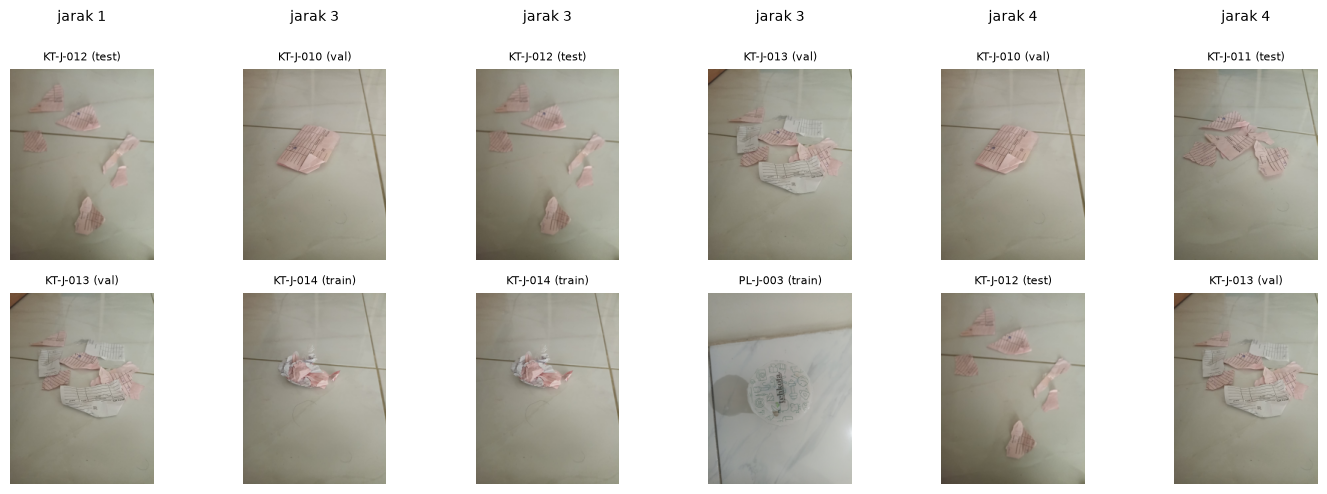

In [79]:
closest = pairs.head(6)

fig, axes = plt.subplots(2, len(closest), figsize=(2.4 * len(closest), 5))
for column, pair in enumerate(closest.itertuples()):
    for row, index in enumerate((pair.a, pair.b)):
        photo = photos.iloc[index]
        axes[row, column].imshow(cv2.cvtColor(thumbs[photo["raw_path"]], cv2.COLOR_BGR2RGB))
        axes[row, column].set_title(f"{photo['object_id']} ({photo['split']})", fontsize=8)
        axes[row, column].axis("off")
    axes[0, column].text(0.5, 1.25, f"jarak {pair.distance}", transform=axes[0, column].transAxes, ha="center")
fig.tight_layout()
fig.savefig(FIGURES / "eda_duplicates.png", dpi=150)

Pasangan dengan jarak paling banyak 10 dianggap kandidat objek mirip. Batas ini jauh di bawah jarak foto dari objek berbeda pada umumnya (median sekitar 31), dan semua kandidat sudah dicek dengan melihat fotonya.

Kelompok yang paling mirip adalah struk pink KT-J-010 sampai KT-J-014 (jarak 1–5), yang tersebar di train, val, dan test. Kelima struk ini merupakan objek berbeda, tetapi tampilannya sangat mirip sehingga perlu diwaspadai sebagai potensi kebocoran ke data evaluasi. Kandidat lainnya adalah objek berbeda yang difoto di lantai, meja, atau karpet yang sama dengan posisi mirip, misalnya kertas putih KT-F-013 dan KT-M-009. Sidik jari 9×8 lebih banyak menangkap pola latar daripada detail objek, jadi setiap kandidat tetap perlu dicek dengan melihat fotonya.

,object_a,split_a,object_b,split_b,distance
0,KT-J-012,test,KT-J-013,val,1
1,KT-J-010,val,KT-J-014,train,3
2,KT-J-012,test,KT-J-014,train,3
3,KT-J-010,val,KT-J-012,test,4
4,KT-J-011,test,KT-J-013,val,4
5,KT-J-011,test,KT-J-014,train,4
6,KT-J-013,val,KT-J-014,train,4
7,KT-J-010,val,KT-J-011,test,5
8,KT-J-010,val,KT-J-013,val,5
9,KT-J-011,test,KT-J-012,test,5


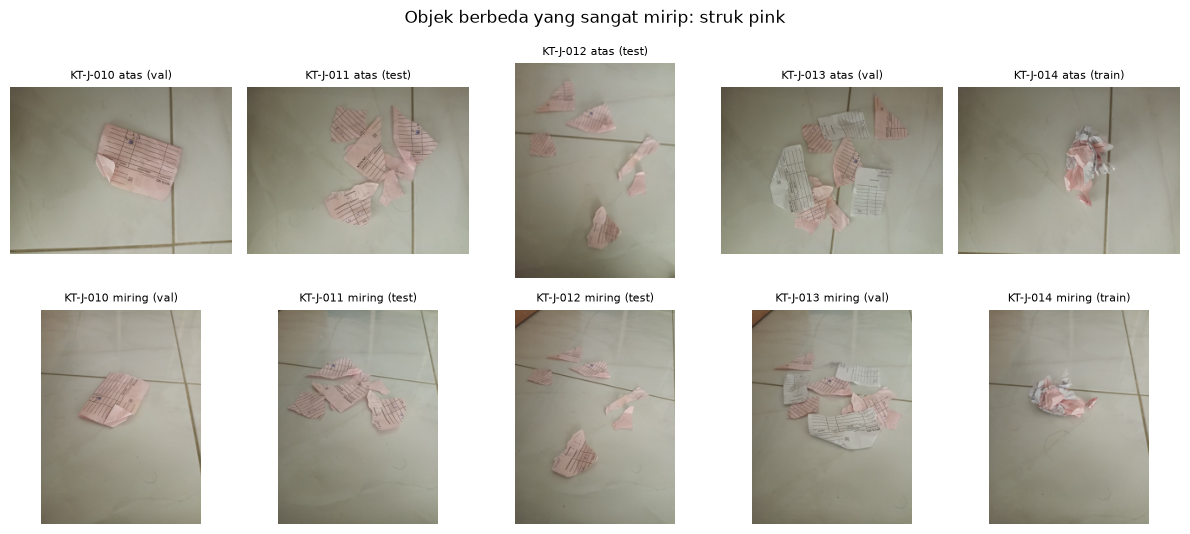

In [80]:
SIMILAR_OBJECTS = ["KT-J-010", "KT-J-011", "KT-J-012", "KT-J-013", "KT-J-014"]

similar = candidates[
    candidates["object_a"].isin(SIMILAR_OBJECTS) & candidates["object_b"].isin(SIMILAR_OBJECTS)
]
display(similar[["object_a", "split_a", "object_b", "split_b", "distance"]].reset_index(drop=True))

fig, axes = plt.subplots(2, len(SIMILAR_OBJECTS), figsize=(2.4 * len(SIMILAR_OBJECTS), 5.4))
for column, object_id in enumerate(SIMILAR_OBJECTS):
    for row, view in enumerate(("atas", "miring")):
        photo = photos[(photos["object_id"] == object_id) & (photos["view"] == view)].iloc[0]
        axes[row, column].imshow(cv2.cvtColor(thumbs[photo["raw_path"]], cv2.COLOR_BGR2RGB))
        axes[row, column].set_title(f"{object_id} {view} ({photo['split']})", fontsize=8)
        axes[row, column].axis("off")
fig.suptitle("Objek berbeda yang sangat mirip: struk pink")
fig.tight_layout()
fig.savefig(FIGURES / "eda_similar_objects.png", dpi=150)

## 7. Contoh foto per kelas

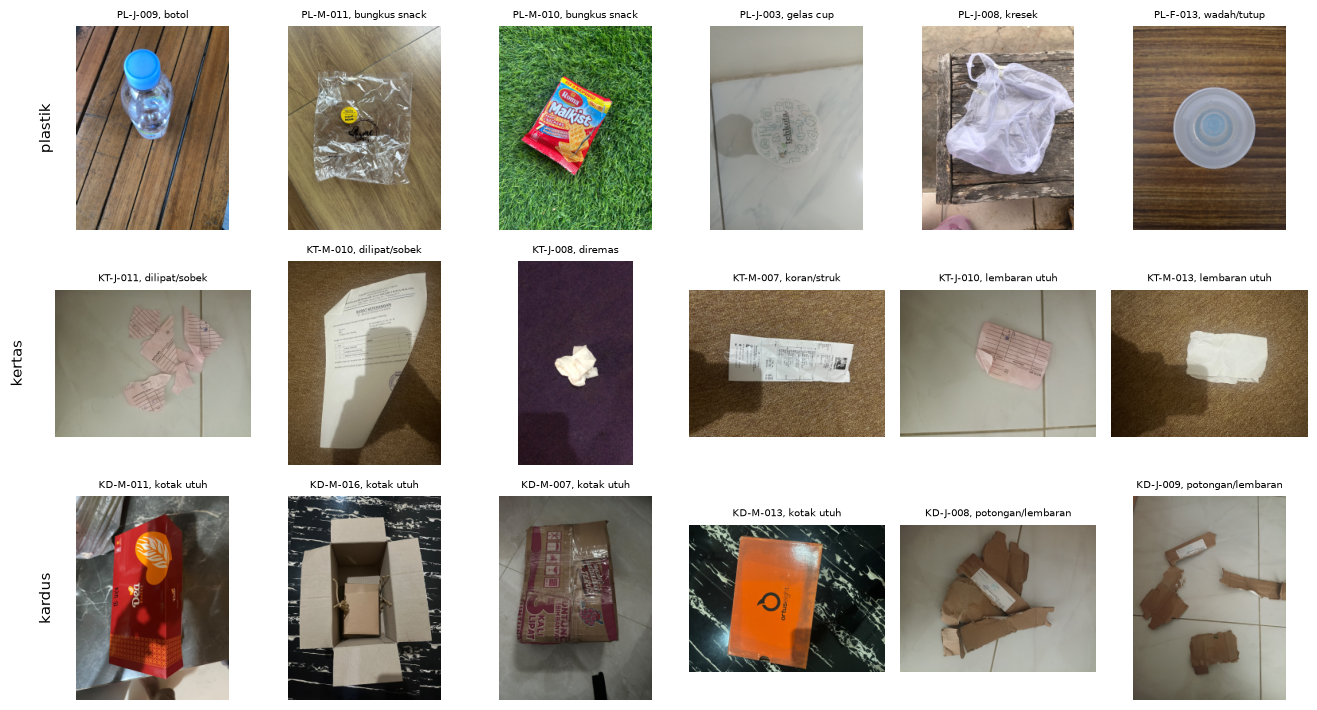

In [81]:
EXAMPLES_PER_CLASS = 6


def pick_examples(label: str) -> pd.DataFrame:
    """Satu foto atas per objek; setiap sub-tipe diwakili dulu, sisa slot diisi acak."""
    pool = photos[(photos["label"] == label) & (photos["view"] == "atas")].sample(frac=1, random_state=42)
    first = pool.drop_duplicates("subtype")
    rest = pool.drop(first.index).head(EXAMPLES_PER_CLASS - len(first))
    return pd.concat([first, rest]).head(EXAMPLES_PER_CLASS).sort_values("subtype")


fig, axes = plt.subplots(len(CLASSES), EXAMPLES_PER_CLASS, figsize=(2.2 * EXAMPLES_PER_CLASS, 2.4 * len(CLASSES)))
for row, label in zip(axes, CLASSES):
    for ax, photo in zip(row, pick_examples(label).itertuples()):
        ax.imshow(cv2.cvtColor(thumbs[photo.raw_path], cv2.COLOR_BGR2RGB))
        ax.set_title(f"{photo.object_id}, {photo.subtype}", fontsize=7)
        ax.axis("off")
    row[0].text(-0.15, 0.5, label, transform=row[0].transAxes, rotation=90, va="center", ha="right", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES / "eda_examples.png", dpi=150)